In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc)

In [2]:
df = pd.read_csv(r"/content/Adm_Pred.csv")
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


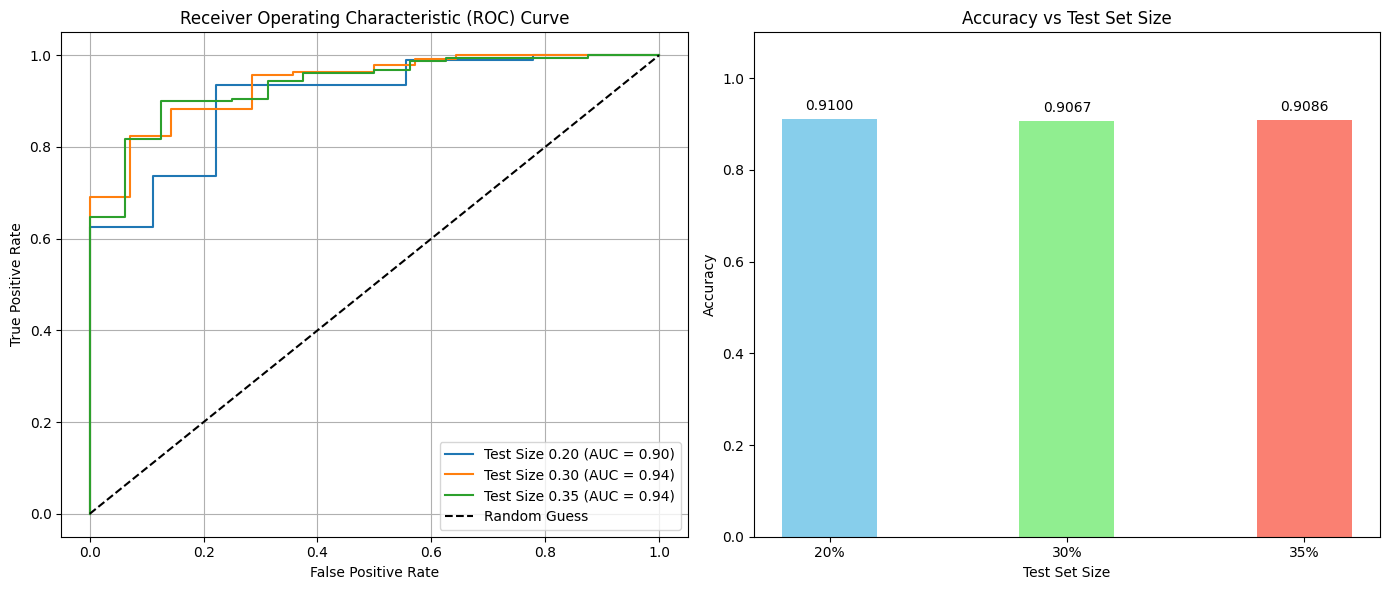

In [18]:
# 1. Clean column names and split features/target
df.columns = df.columns.str.strip()
X = df.drop(columns=['Chance of Admit'])
y = df['Chance of Admit'].apply(lambda x: 1 if x >= 0.5 else 0)

# 2. Evaluate different splits, compute metrics, and plot ROC curves
splits = [0.20, 0.30, 0.35]
accuracy = []

plt.figure(figsize=(14, 6))

# Subplot 1: ROC Curves
plt.subplot(1, 2, 1)
for i in splits:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=i, random_state=42)

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_prob = model.predict(X_test)
    y_pred = [1 if p >= 0.5 else 0 for p in y_prob]

    # Calculate accuracy
    acc = accuracy_score(y_test, y_pred)
    accuracy.append(acc)

    # Calculate ROC Curve & AUC
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'Test Size {i:.2f} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)

# Subplot 2: Corrected Bar Plot of Accuracies
plt.subplot(1, 2, 2)
# Use string representations on the x-axis or a tiny width (like 0.03) to prevent overlapping bars
split_labels = [f'{int(s*100)}%' for s in splits]
plt.bar(split_labels, accuracy, width=0.4, color=['skyblue', 'lightgreen', 'salmon'])
plt.xlabel('Test Set Size')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Test Set Size')
plt.ylim(0, 1.1)
for index, val in enumerate(accuracy):
    plt.text(index, val + 0.02, f'{val:.4f}', ha='center')

plt.tight_layout()
plt.show()

In [12]:
splits = [0.20, 0.30, 0.35]
accuracy=[]

for i in splits:
  X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=i, random_state=42)

  model = LinearRegression()
  model.fit(X_train, y_train)

  y_prob = model.predict(X_test)
  y_pred = [1 if p >= 0.5 else 0 for p in y_prob]
  acc = accuracy_score(y_test, y_pred)
  accuracy.append(acc)

  print("Accuracy:", acc)

  # e) Confusion matrix
  cm = confusion_matrix(y_test, y_pred)
  print("Confusion Matrix:\n", cm)

  # f) Precision, Recall, F1
  precision = precision_score(y_test, y_pred)
  recall = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)

  print("Precision:", precision)
  print("Recall:", recall)
  print("F1-Score:", f1)

  print()

Accuracy: 0.91
Confusion Matrix:
 [[ 0  9]
 [ 0 91]]
Precision: 0.91
Recall: 1.0
F1-Score: 0.9528795811518325

Accuracy: 0.9066666666666666
Confusion Matrix:
 [[  0  14]
 [  0 136]]
Precision: 0.9066666666666666
Recall: 1.0
F1-Score: 0.951048951048951

Accuracy: 0.9085714285714286
Confusion Matrix:
 [[  0  16]
 [  0 159]]
Precision: 0.9085714285714286
Recall: 1.0
F1-Score: 0.9520958083832335

